# Clustering Algorithms
### CSEE / ENGR 8300

Contents:

1. Introduction
2. Principles, worked by hand on toy data: distance, k-means, choosing $k$, hierarchical clustering, DBSCAN, Gaussian mixtures
3. Comparison of algorithms on different data shapes
4. Summary

It builds on the SensorAI unsupervised-learning tutorial (`tutorials/unsupervised_tutorial2.ipynb`, github.com/wsonguga/SensorAI);
the step-by-step k-means cell in Part 3 is taken from it. Requirements: `numpy`, `pandas`, `matplotlib`, `scipy`, `scikit-learn`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN, SpectralClustering
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score
from sklearn.datasets import make_blobs, make_moons, make_circles

COLORS = ["#ba0c2f", "#1f78b4", "#d6a461", "#33a02c", "#7b4fa0", "#8a867f"]
plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.25, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.precision", 2)

---
## 1 · Introduction

**Clustering** divides unlabeled data into groups so that points in the same group are similar and points in different groups are not.
Unlike classification, there are no labels to learn from. Each method answers three questions: how similarity is measured,
what a cluster looks like, and whether the number of clusters $k$ is given or found.

| Family | Idea of a cluster | Example | $k$ given? |
|---|---|---|---|
| Centroid-based | points close to a centre | k-means | yes |
| Hierarchical | a tree of nested groups | agglomerative (single, complete, Ward) | cut the tree |
| Density-based | dense regions separated by sparse ones | DBSCAN, OPTICS | no |
| Distribution-based | points drawn from one distribution | Gaussian mixture (EM) | yes |
| Graph-based | well-connected part of a similarity graph | spectral clustering | yes |

---
## 2 · Principles

### 2.1 Distance

Euclidean distance $d(\mathbf p,\mathbf q)=\sqrt{\sum_j (p_j-q_j)^2}$; Manhattan distance $d_1(\mathbf p,\mathbf q)=\sum_j |p_j-q_j|$.

Toy data used in this part:

| Point | A | B | C | D | E | F |
|---|---|---|---|---|---|---|
| $x$ | 1 | 1.5 | 3 | 5 | 3.5 | 4.5 |
| $y$ | 1 | 2 | 3.5 | 7 | 5 | 5 |

By hand: $d(C,D)=\sqrt{2^2+3.5^2}=4.03$ and $d_1(C,D)=2+3.5=5.5$.

In [2]:
toy = pd.DataFrame({"x": [1, 1.5, 3, 5, 3.5, 4.5], "y": [1, 2, 3.5, 7, 5, 5]}, index=list("ABCDEF"))
P = toy.to_numpy(float)
D = np.sqrt(((P[:, None] - P[None]) ** 2).sum(-1))
pd.DataFrame(D, index=toy.index, columns=toy.index)

,A,B,C,D,E,F
A,0.00,1.12,3.20,7.21,4.72,5.32
B,1.12,0.00,2.12,6.10,3.61,4.24
C,3.20,2.12,0.00,4.03,1.58,2.12
D,7.21,6.10,4.03,0.00,2.50,2.06
E,4.72,3.61,1.58,2.50,0.00,1.00
F,5.32,4.24,2.12,2.06,1.00,0.00


### 2.2 k-means

k-means chooses $k$ centres $\boldsymbol\mu_j$ to minimise

$$\mathrm{SSE}=\sum_{j=1}^{k}\sum_{\mathbf x_i\in C_j}\lVert\mathbf x_i-\boldsymbol\mu_j\rVert^2 ,$$

alternating two steps until no point changes cluster: **assign** each point to its nearest centre, then **update** each centre to the mean of its points.
Neither step increases the SSE, so the algorithm stops, but the result can depend on the starting centres.

**By hand, $k=2$, starting centres $A$ and $D$.** Iteration 1 assigns A, B, C to cluster 1 and D, E, F to cluster 2
(for C: $d^2=10.25$ to $\mu_1$ and $16.25$ to $\mu_2$). The new centres are $\mu_1=(1.83,\,2.17)$ and $\mu_2=(4.33,\,5.67)$.
In iteration 2 no point changes (C: $3.14$ vs $6.47$), so k-means has converged with $\mathrm{SSE}=9.17$.

In [3]:
centres = P[[0, 3]].copy()
labels = None
for it in range(1, 10):
    d2 = ((P[:, None] - centres[None]) ** 2).sum(-1)
    new = d2.argmin(1)
    print(f"Iteration {it}: centres {centres.round(2).tolist()}, clusters {(new + 1).tolist()}")
    if labels is not None and (new == labels).all():
        break
    labels = new
    centres = np.array([P[labels == j].mean(0) for j in range(2)])
sse = sum(((P[labels == j] - centres[j]) ** 2).sum() for j in range(2))
print("SSE =", round(sse, 2))

Iteration 1: centres [[1.0, 1.0], [5.0, 7.0]], clusters [1, 1, 1, 2, 2, 2]
Iteration 2: centres [[1.83, 2.17], [4.33, 5.67]], clusters [1, 1, 1, 2, 2, 2]
SSE = 9.17


### 2.3 Choosing $k$ and checking each point

The SSE always decreases as $k$ grows, so we look for an **elbow**. The **silhouette** of point $i$ is

$$s(i)=\frac{b(i)-a(i)}{\max\{a(i),\,b(i)\}},$$

where $a(i)$ is the mean distance to the other points of its own cluster and $b(i)$ the mean distance to the points of the nearest other cluster.
For C: $a=\tfrac12(3.20+2.12)=2.66$, $b=\tfrac13(4.03+1.58+2.12)=2.58$, so $s(C)=-0.03$: C lies on the border between the clusters.

In [4]:
sse_k = [KMeans(n_clusters=k, n_init=20, random_state=0).fit(P).inertia_ for k in range(1, 6)]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].plot(range(1, 6), sse_k, "o-"); axes[0].set(xlabel="k", ylabel="SSE", title="Elbow")
s = silhouette_samples(P, labels)
axes[1].bar(toy.index, s, color=[COLORS[l] for l in labels]); axes[1].axhline(0, color="k", lw=0.8)
axes[1].set(ylabel="silhouette", title=f"Silhouette per point (mean {s.mean():.2f})")
plt.tight_layout(); plt.show()

<Figure size 1000x350 with 2 Axes>

### 2.4 Hierarchical clustering

Agglomerative clustering starts with every point alone and repeatedly merges the two closest clusters. The **linkage** defines the distance between groups:
single (closest pair), complete (farthest pair), average (mean of all pairs), Ward (increase in SSE).

**By hand** on $A=1, B=2, C=5, D=7, E=12$: both linkages merge {A,B} at 1 and {C,D} at 2. Single linkage then merges {A,B,C,D} at $|2-5|=3$ and adds E at 5;
complete linkage merges at $|1-7|=6$ and adds E at $|1-12|=11$.

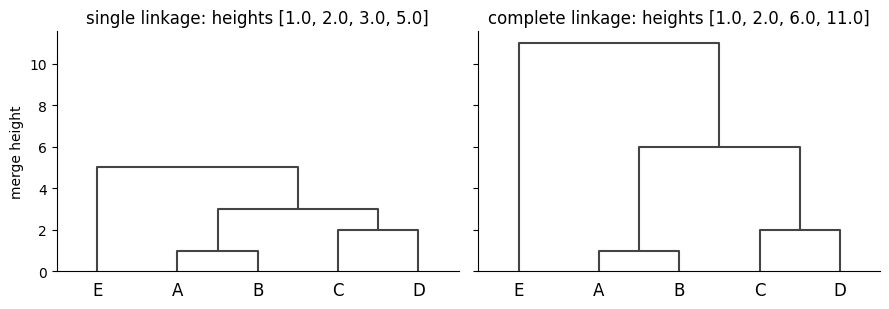

In [5]:
x1 = np.array([[1], [2], [5], [7], [12]])
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2), sharey=True)
for ax, method in zip(axes, ["single", "complete"]):
    Z = linkage(x1, method)
    dendrogram(Z, labels=list("ABCDE"), ax=ax, color_threshold=0, above_threshold_color="#444")
    ax.set_title(f"{method} linkage: heights {Z[:, 2].tolist()}"); ax.grid(False)
axes[0].set_ylabel("merge height"); plt.tight_layout(); plt.show()

### 2.5 DBSCAN

DBSCAN has a radius $\varepsilon$ and a count `minPts`. A **core** point has at least `minPts` points within $\varepsilon$ (itself included);
a **border** point is not core but lies within $\varepsilon$ of a core point; all other points are **noise**. The number of clusters is not given in advance.

**By hand** with $\varepsilon=1.5$, `minPts` = 3: P1–P4 are core, P5 is a border point (1.30 from P4), P6–P8 form a second cluster, P9 is noise.

In [6]:
Q = np.array([[1, 1], [2, 1], [1, 2], [2, 2], [3.3, 2], [6, 6], [7, 6], [6.5, 6.8], [9, 1]])
db = DBSCAN(eps=1.5, min_samples=3).fit(Q)
core = np.isin(np.arange(len(Q)), db.core_sample_indices_)
neighbours = (np.sqrt(((Q[:, None] - Q[None]) ** 2).sum(-1)) <= 1.5).sum(1)
pd.DataFrame({"neighbours within 1.5": neighbours,
              "type": np.where(core, "core", np.where(db.labels_ == -1, "noise", "border")),
              "cluster": db.labels_}, index=[f"P{i + 1}" for i in range(len(Q))])

,neighbours within 1.5,type,cluster
P1,4,core,0
P2,4,core,0
P3,4,core,0
P4,5,core,0
P5,2,border,0
P6,3,core,1
P7,3,core,1
P8,3,core,1
P9,1,noise,-1


### 2.6 Gaussian mixtures

A Gaussian mixture models the data as $p(\mathbf x)=\sum_{j=1}^{k}\pi_j\,\mathcal N(\mathbf x\mid\boldsymbol\mu_j,\boldsymbol\Sigma_j)$
and gives each point a probability of belonging to each component. It is fitted with the EM algorithm:
the E-step computes these probabilities, the M-step updates $\pi_j$, $\boldsymbol\mu_j$, $\boldsymbol\Sigma_j$.
k-means corresponds to the limiting case of equal spherical covariances shrinking to zero, where the probabilities become 0 or 1.
On the toy data only C is uncertain.

In [7]:
gmm = GaussianMixture(n_components=2, covariance_type="spherical", random_state=0).fit(P)
prob = gmm.predict_proba(P)[:, np.argsort(gmm.means_[:, 0])]
pd.DataFrame(prob, index=toy.index, columns=["P(cluster 1)", "P(cluster 2)"]).round(3)

,P(cluster 1),P(cluster 2)
A,1.00e+00,0.00
B,1.00e+00,0.00
C,8.74e-01,0.13
D,0.00e+00,1.00
E,2.00e-03,1.00
F,0.00e+00,1.00


---
## 3 · Comparison of algorithms

**k-means step by step (from the SensorAI tutorial).** Edit `INITIAL_CENTROIDS` or switch to Dataset B and re-run:
a different start can give a different result, and two long rows are split left/right because that gives a lower SSE.

Data shape: (30, 2), K=3


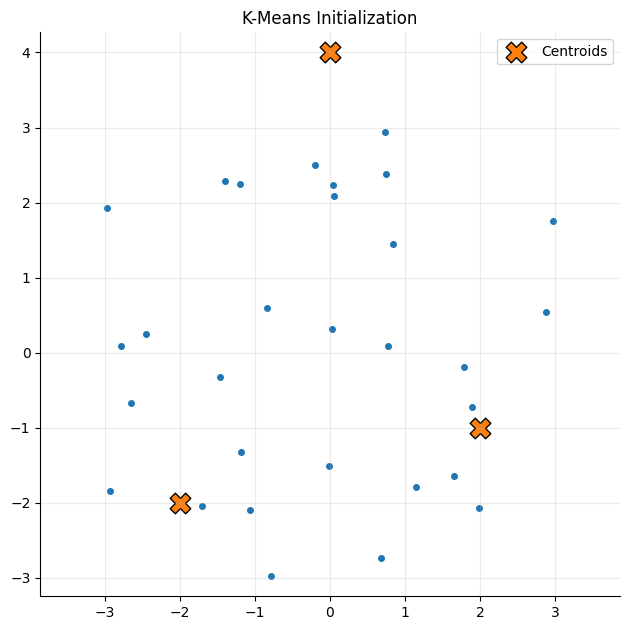

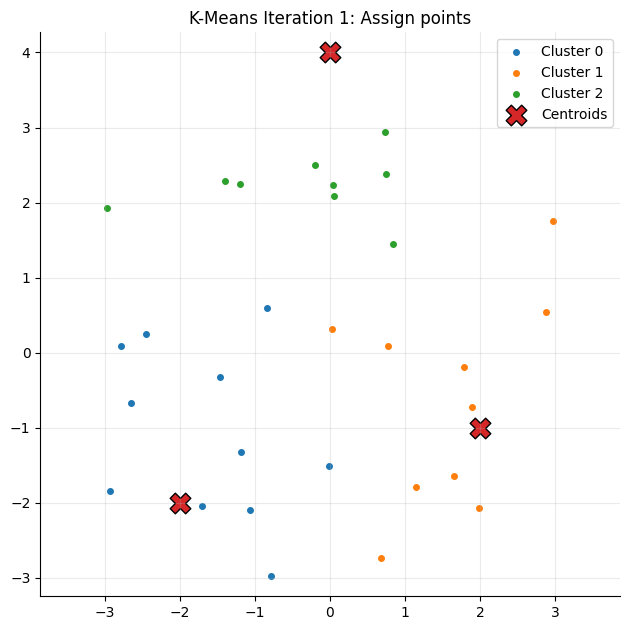

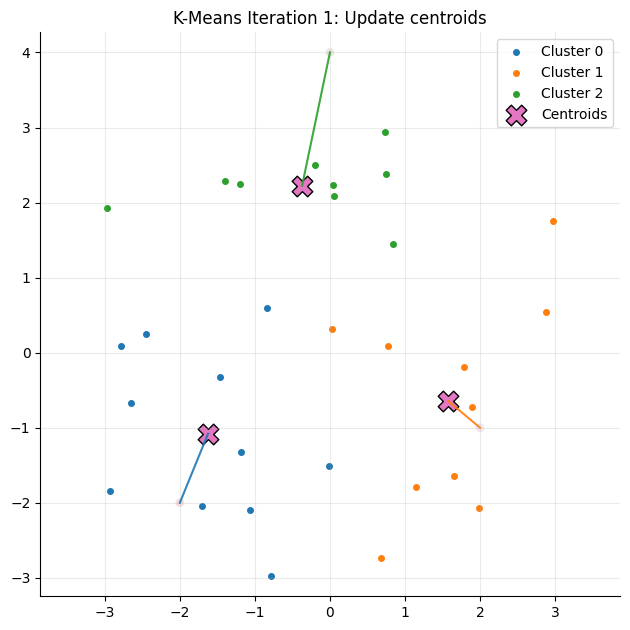

Iteration 1: centroid shift = 2.138718


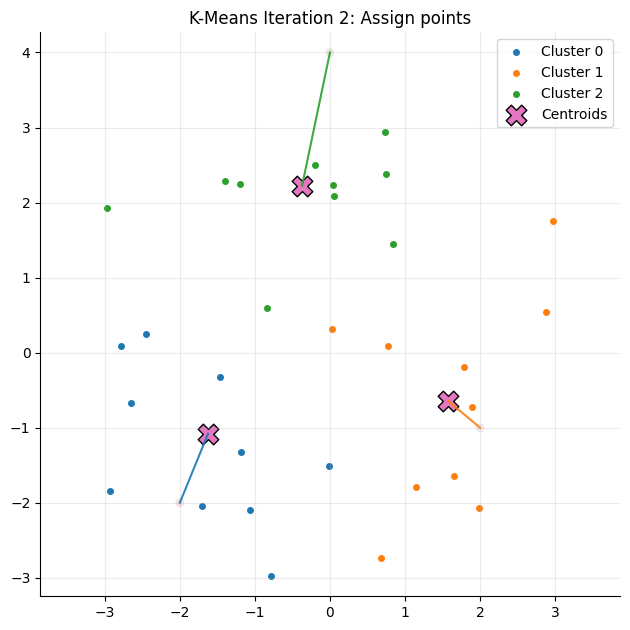

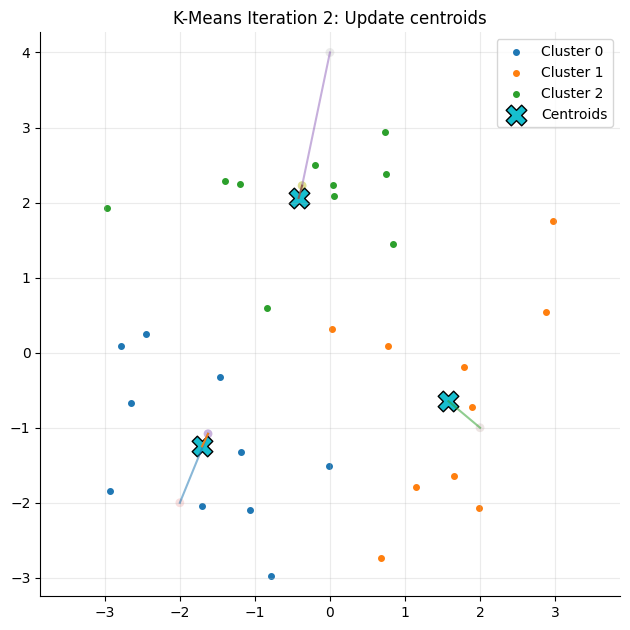

Iteration 2: centroid shift = 0.251116


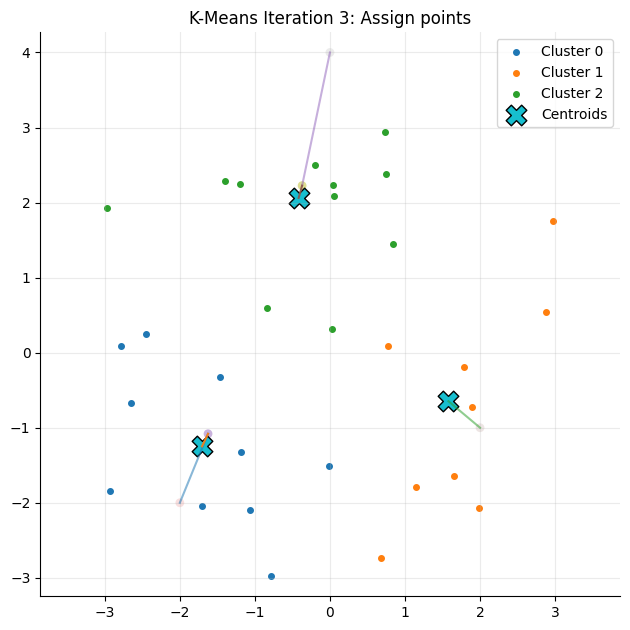

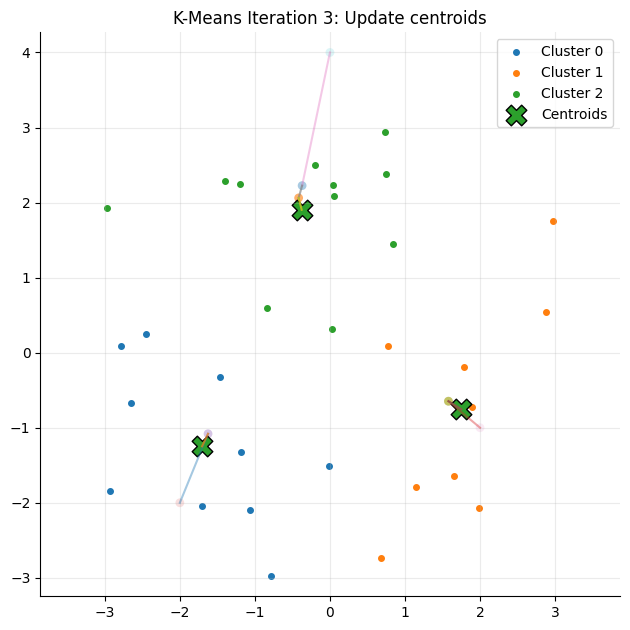

Iteration 3: centroid shift = 0.260727
Converged after 3 iteration(s): assignments are unchanged.


In [8]:
# K-MEANS STEPS: SEEDED DATA AND EDITABLE INITIAL CENTROIDS
import numpy as np
import matplotlib.pyplot as plt

SEED = 7
MAX_ITER = 4
TOL = 1e-3
SHOW_LABEL_TEXT = False

# # Activate exactly one dataset block by commenting/uncommenting its code.
# # Each block includes editable initial centroids; the number of rows sets K.
# # Changing the initial centroids or K does not change the generated data.
data_rng = np.random.default_rng(SEED)

# # Dataset A (active): 30 uniform random points in [-3, 3] x [-3, 3].
X = data_rng.uniform(-3.0, 3.0, size=(30, 2))

# # Edit these [x, y] coordinates, or add/remove rows to change K.
INITIAL_CENTROIDS = np.array([
	[-2.0, -2.0],
	[2.0, -1.0],
	[0.0, 4.0],
], dtype=float)

# Dataset B (inactive): two long, closely spaced horizontal rows.
# Comment out Dataset A's X and INITIAL_CENTROIDS, then uncomment this block.
# The suggested two initial centers demonstrate a left/right split, with each
# cluster containing points from BOTH rows. K-Means minimizes squared distances;
# for this geometry, a left/right split has lower SSE than grouping by row.
# Other initial centers can produce different local solutions.
# line_x = np.linspace(-6.0, 6.0, 16)
# X = np.vstack([
#     np.column_stack((line_x, data_rng.normal(-1.0, 0.06, size=len(line_x)))),
#     np.column_stack((line_x, data_rng.normal(1.0, 0.06, size=len(line_x)))),
# ])
# INITIAL_CENTROIDS = np.array([
#     [-3.0, 0.0],
#     [3.0, 0.0],
# ], dtype=float)

# End of dataset selection. Shared K-Means code starts here.
N = X.shape[0]

if INITIAL_CENTROIDS.ndim != 2 or INITIAL_CENTROIDS.shape[1] != 2 or not np.isfinite(INITIAL_CENTROIDS).all():
	raise ValueError("INITIAL_CENTROIDS must contain finite [x, y] coordinates.")
K = len(INITIAL_CENTROIDS)
if not 1 <= K <= N:
	raise ValueError(f"Specify between 1 and {N} initial centroids.")

centroids = INITIAL_CENTROIDS.copy()
# Keep empty-cluster replacements reproducible without sharing the data generator.
empty_cluster_rng = np.random.default_rng(SEED)

def assign_labels(X, centroids):
	distances = np.linalg.norm(X[:, None, :] - centroids[None, :, :], axis=2)
	return np.argmin(distances, axis=1)

def update_centroids(X, labels, K):
	new_centroids = np.zeros((K, 2), dtype=X.dtype)
	for k in range(K):
		pts = X[labels == k]
		if len(pts) == 0:
			new_centroids[k] = X[empty_cluster_rng.integers(0, X.shape[0])]
		else:
			new_centroids[k] = pts.mean(axis=0)
	return new_centroids

centroid_history = [centroids.copy()]
def plot_state(X, labels, centroids, iteration, phase, show_label_text=SHOW_LABEL_TEXT):
	
	plt.figure(figsize=(6.4, 6.4))
	if labels is None:
		plt.scatter(X[:,0], X[:,1], s=16)
	else:
		for k in range(centroids.shape[0]):
			pts = X[labels == k]
			if pts.size > 0:
				plt.scatter(pts[:,0], pts[:,1], s=16, label=f"Cluster {k}")
				if show_label_text:
					for p in pts:
						plt.text(p[0], p[1], str(k), fontsize=6, alpha=0.45)

	H = len(centroid_history)
	for k in range(centroids.shape[0]):
		traj = np.array([centroid_history[h][k] for h in range(H)])  # (H,2)
		for h in range(1, H):
			alpha = 0.15 + 0.75 * (h / (H - 1)) if H > 1 else 0.9
			plt.plot(traj[h-1:h+1,0], traj[h-1:h+1,1], linewidth=1.5, alpha=alpha)
		for h in range(H-1):
			alpha = 0.15 + 0.7 * (h / (H - 1)) if H > 1 else 0.5
			plt.scatter(traj[h,0], traj[h,1], s=40, marker='o', alpha=alpha, edgecolor='none')

	plt.scatter(centroids[:,0], centroids[:,1], s=220, marker='X', edgecolor='black', linewidths=1.0, label='Centroids')
	# Equal axis units preserve the geometry of long, thin datasets.
	plt.gca().set_aspect("equal", adjustable="datalim")
	plt.title("K-Means Initialization" if iteration == 0
		else f"K-Means Iteration {iteration}: {phase}")
	plt.legend(loc="best")
	plt.tight_layout()
	plt.show()

print(f"Data shape: {X.shape}, K={K}")

plot_state(X, labels=None, centroids=centroids, iteration=0, phase="Initialization")
labels = None
for it in range(1, MAX_ITER + 1):
	new_labels = assign_labels(X, centroids)
	# After an update, unchanged assignments mean the nonempty cluster means
	# are already final. Check before drawing another pair of identical plots.
	if (labels is not None and np.array_equal(new_labels, labels)
			and np.all(np.bincount(new_labels, minlength=K) > 0)):
		print(f"Converged after {it - 1} iteration(s): assignments are unchanged.")
		break
	labels = new_labels
	plot_state(X, labels=labels, centroids=centroids, iteration=it, phase="Assign points")
	new_centroids = update_centroids(X, labels, K)
	centroid_history.append(new_centroids.copy())
	plot_state(X, labels=labels, centroids=new_centroids, iteration=it, phase="Update centroids")

	shift = np.linalg.norm(new_centroids - centroids)
	print(f"Iteration {it}: centroid shift = {shift:.6f}")
	centroids = new_centroids
	if shift < TOL:
		print("Converged: centroid shift is below TOL.")
		break

**Different data shapes.** Each panel shows the adjusted Rand index (ARI) against the generating groups: 1 means identical partitions, about 0 means chance level.

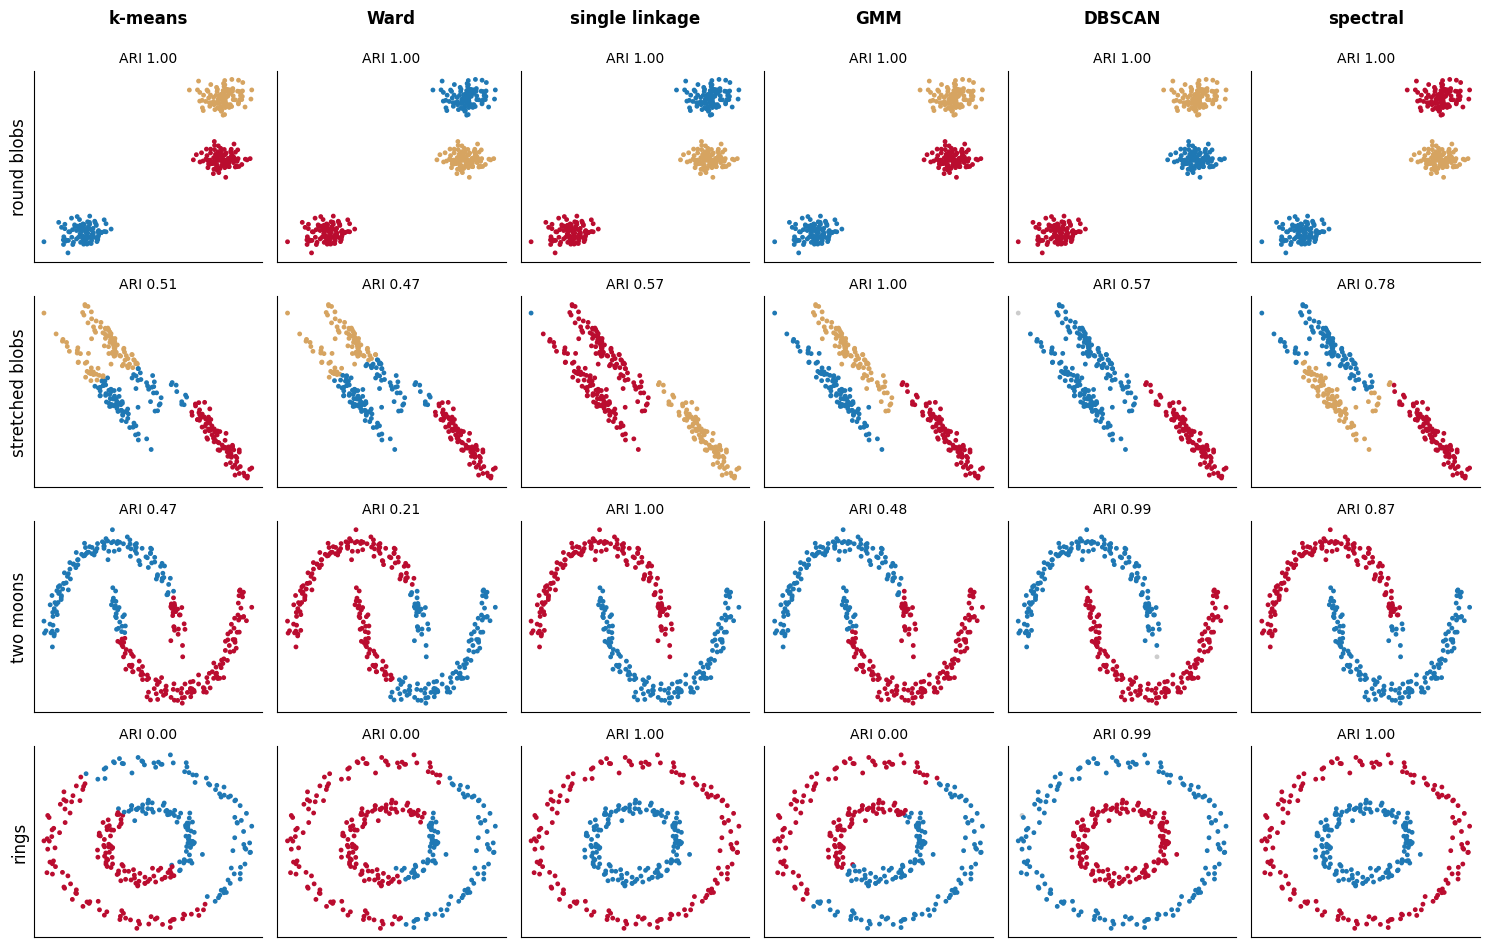

In [9]:
import warnings
warnings.filterwarnings("ignore", message="Graph is not fully connected")  # spectral embedding on the separated blobs
Xa, ya = make_blobs(n_samples=300, centers=3, random_state=170)
shapes = {"round blobs": make_blobs(n_samples=300, centers=3, cluster_std=1.0, random_state=8),
          "stretched blobs": (Xa @ np.array([[0.6, -0.64], [-0.41, 0.85]]), ya),
          "two moons": make_moons(n_samples=300, noise=0.06, random_state=0),
          "rings": make_circles(n_samples=300, factor=0.45, noise=0.05, random_state=0)}
models = lambda k: {"k-means": KMeans(n_clusters=k, n_init=10, random_state=0),
                    "Ward": AgglomerativeClustering(n_clusters=k, linkage="ward"),
                    "single linkage": AgglomerativeClustering(n_clusters=k, linkage="single"),
                    "GMM": GaussianMixture(n_components=k, covariance_type="full", random_state=0),
                    "DBSCAN": DBSCAN(eps=0.3, min_samples=5),
                    "spectral": SpectralClustering(n_clusters=k, affinity="nearest_neighbors", n_neighbors=10, random_state=0)}
fig, axes = plt.subplots(4, 6, figsize=(15, 9.5))
for r, (name, (X, y)) in enumerate(shapes.items()):
    X = StandardScaler().fit_transform(X)
    for c, (alg, model) in enumerate(models(len(set(y))).items()):
        lab = model.fit_predict(X)
        cols = np.array(COLORS)[lab % len(COLORS)]; cols[lab == -1] = "#cccccc"
        ax = axes[r, c]; ax.scatter(X[:, 0], X[:, 1], s=6, c=cols)
        ax.set_title(f"ARI {abs(adjusted_rand_score(y, lab)):.2f}" if abs(adjusted_rand_score(y, lab)) < 0.005 else f"ARI {adjusted_rand_score(y, lab):.2f}", fontsize=10); ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
        if r == 0: ax.text(0.5, 1.25, alg, transform=ax.transAxes, ha="center", fontsize=12, fontweight="bold")
        if c == 0: ax.set_ylabel(name, fontsize=12)
plt.tight_layout(); plt.show()

---
## 4 · Summary

| Method | Idea | $k$ given? | Suits | Sensitive to |
|---|---|---|---|---|
| k-means | nearest centre, minimise SSE | yes | round groups, large data | start, scaling, outliers |
| Hierarchical | merge closest groups | cut the tree | seeing the structure | linkage, $O(n^2)$ memory |
| DBSCAN | dense regions + noise | no | any shape, noise | $\varepsilon$, varying density |
| GMM | mixture of Gaussians | yes | elliptical groups | local optima |

**References.** SensorAI tutorials (github.com/wsonguga/SensorAI); scikit-learn user guide, *Clustering*;
Ester et al. (1996), DBSCAN, KDD-96; Rousseeuw (1987), silhouettes; Hastie, Tibshirani & Friedman, *The Elements of Statistical Learning*, §14.3.